In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from statsmodels.tsa.seasonal import seasonal_decompose

from utils.Preprocessing    import PreProcessData
from utils.plotFigures      import linePlot, lineAndScatterPlot, scatterPlot3D

In [3]:
# preData = PreProcessData()
# preData.dataLoading(typeFile='h5')
# df      = preData.splitTimeSeries()
# dfRaw = preData.crusher1Raw

# scaler  = StandardScaler()
# preData.normalizeData(scaler);

In [2]:
df_raw = pd.read_hdf('data/3200CR001_26-3-2024.h5')

In [13]:
df = df_raw.copy()
df.drop_duplicates(subset='tiempo', inplace=True)
df.loc[:, df.select_dtypes('number').columns] = df.select_dtypes('number').interpolate(method='linear')
#df.set_index('tiempo', inplace=True)

In [14]:
# df['corriente(A)'].resample('h').sum()

In [15]:
df_filtered = df[df['tiempo'].between('2023-01-01 00:00:00', '2023-02-01 00:00:00')]
df_filtered.set_index('tiempo', inplace=True)

In [26]:
seasonal_decompose(df_filtered['corriente(A)'].resample('1T').sum(), model = 'additive')

C:\Users\CAEX\AppData\Local\Temp\ipykernel_17708\957049880.py:1: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  seasonal_decompose(df_filtered['corriente(A)'].resample('1T').sum(), model = 'additive')


ValueError: freq MIN not understood. Please report if you think this is in error.

In [22]:
from statsmodels.tsa.seasonal import seasonal_decompose
def decompose(df, column_name):
    """
    A function that returns the trend, seasonality and residual captured by applying both multiplicative and
    additive model.
    df -> DataFrame
    column_name -> column_name for which trend, seasonality is to be captured
    """
    #result_mul = seasonal_decompose(df[column_name], model='multiplicative', extrapolate_trend = 'freq')
    result_add = seasonal_decompose(df[column_name].resample('h').mean(), model = 'additive') #, extrapolate_trend='freq')

    plt.rcParams.update({'figure.figsize': (20, 10)})
    #result_mul.plot().suptitle('Multiplicative Decompose', fontsize=30)
    result_add.plot().suptitle('Additive Decompose', fontsize=30)
    plt.show()
    
    #return result_mul, result_add
    return result_add

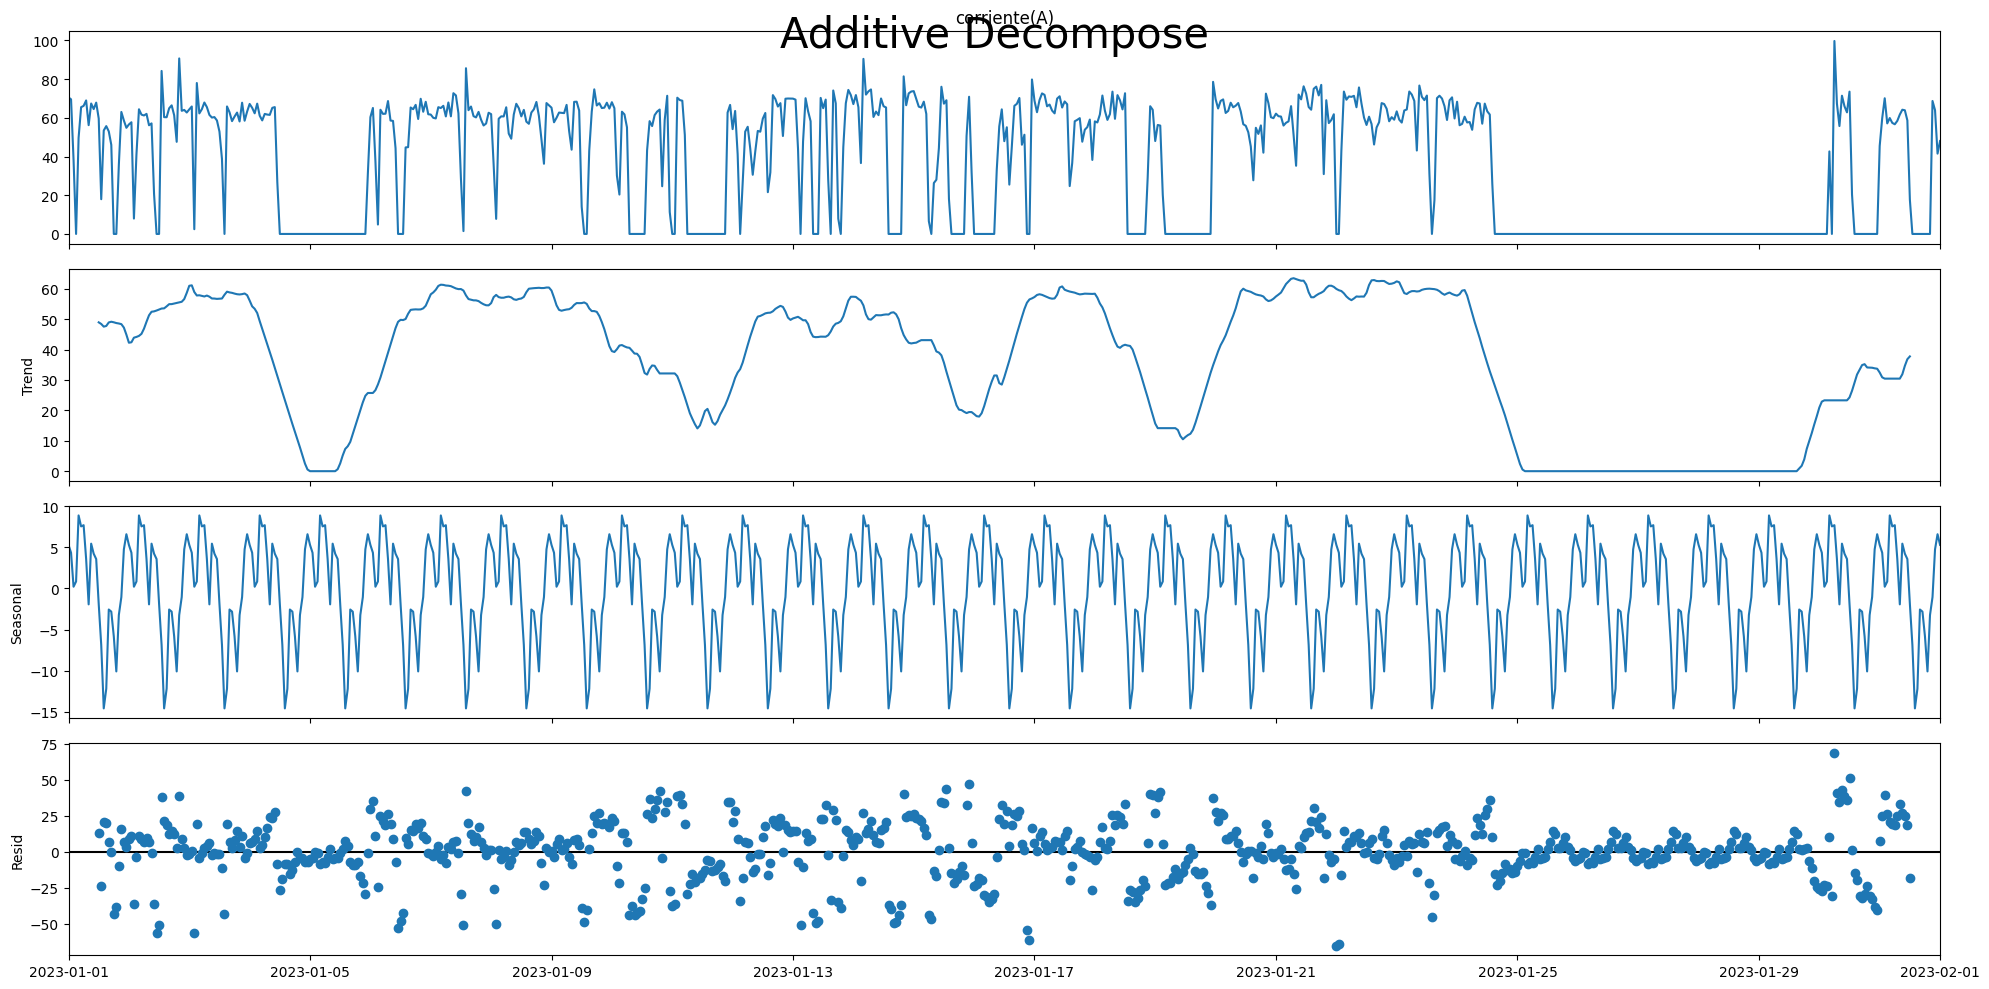

In [23]:
result_add = decompose(df_filtered, 'corriente(A)')